# Assignment 5 — Timeseries **or** Text

**DATAX504** · Due end of Week 10

**Chosen track: A — Timeseries (Jena climate).** Forecast the next 7 hourly temperature values.

| Track | Goal | Moodle `a5_metric` |
|-------|------|--------------------|
| **A** — Timeseries | Forecast **7** future steps of temperature from Jena climate | MAE |
| **B** — Text | Classify AG News topics (4 classes) | Accuracy (%) |

## AI disclosure

| Field | Your answer |
|-------|-------------|
| Tool / model | ChatGPT|
| Used for | Help with the code, fixing problems, explaining steps |
| Verified how | Ran the notebook myself in Google Colab, checked the results and charts, compared my MAE (1.091 °C) with the baseline (2.286 °C) |
| Not used for | Choosing the track, running the notebook, or submitting the assignment |

In [1]:
TRACK = "A"  # "A" or "B" — Moodle a5_track

import os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
print("Selected track:", TRACK, "| Keras", keras.__version__)

Selected track: A | Keras 3.13.2


---
# Track A — Timeseries (Jena)

**Design decisions**
- Raw data is every 10 min; I subsample to **hourly** so 1 step = 1 hour. Forecast target = temperature at the next **7 hours**.
- Lookback = **120 hours** (5 days).
- **Chronological** split 50 / 25 / 25 (train / val / test). No shuffling of the split, windows never cross split boundaries.
- Z-score normalisation with **training-portion statistics only**.
- Model predicts all 7 steps at once (multi-output), Conv1D + LSTM.
- MAE reported in **°C** (multiply normalised MAE by the training temperature std).

In [2]:
if TRACK == "A":
    # ---------- 1. Load ----------
    URL = "https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip"
    zip_path = keras.utils.get_file("jena_climate_2009_2016.csv.zip", origin=URL)
    folder = os.path.dirname(zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(folder)
    df = pd.read_csv(os.path.join(folder, "jena_climate_2009_2016.csv"))
    df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")

    # ---------- 2. Clean + hourly subsample ----------
    df = df.iloc[5::6].reset_index(drop=True)          # 10-min -> hourly
    for c in ["wv (m/s)", "max. wv (m/s)"]:
        df[c] = df[c].replace(-9999.0, 0.0)            # sentinel error values
    # cyclical time features
    hod = df["Date Time"].dt.hour
    doy = df["Date Time"].dt.dayofyear
    df["hour_sin"] = np.sin(2*np.pi*hod/24);  df["hour_cos"] = np.cos(2*np.pi*hod/24)
    df["doy_sin"]  = np.sin(2*np.pi*doy/365.25); df["doy_cos"] = np.cos(2*np.pi*doy/365.25)

    feat_df = df.drop(columns=["Date Time", "wd (deg)"])  # wd is circular; sin/cos of time used instead
    feature_names = list(feat_df.columns)
    t_idx = feature_names.index("T (degC)")
    data = feat_df.values.astype("float32")
    print("Hourly rows:", len(data), "| features:", len(feature_names))

    # ---------- 3. Chronological split + train-only normalisation ----------
    n = len(data)
    n_tr, n_va = int(0.50*n), int(0.25*n)
    train_raw, val_raw, test_raw = data[:n_tr], data[n_tr:n_tr+n_va], data[n_tr+n_va:]
    mu, sd = train_raw.mean(axis=0), train_raw.std(axis=0) + 1e-8
    train, val, test = [(a-mu)/sd for a in (train_raw, val_raw, test_raw)]
    T_mean, T_std = float(mu[t_idx]), float(sd[t_idx])
    print(f"Split sizes  train/val/test: {len(train)}/{len(val)}/{len(test)}")

    # ---------- 4. Windowing ----------
    LOOKBACK, H, BATCH = 120, 7, 256

    def make_ds(x, shuffle):
        m = len(x)
        # y[j, k] = T at time j+1+k  (next H steps after time j)
        y = np.stack([x[1+k : m-H+1+k, t_idx] for k in range(H)], axis=1)
        return keras.utils.timeseries_dataset_from_array(
            x[:m-H], y[LOOKBACK-1:], sequence_length=LOOKBACK,
            batch_size=BATCH, shuffle=shuffle, seed=SEED)

    train_ds, val_ds, test_ds = make_ds(train, True), make_ds(val, False), make_ds(test, False)
    xb, yb = next(iter(train_ds))
    print("X batch:", tuple(xb.shape), "| y batch:", tuple(yb.shape))

13565642/13565642 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Hourly rows: 70075 | features: 17
Split sizes  train/val/test: 35037/17518/17520
X batch: (256, 120, 17) | y batch: (256, 7)


In [3]:
if TRACK == "A":
    # ---------- 5. Baseline: persistence (repeat last observed temperature) ----------
    y_true = np.concatenate([np.asarray(b) for _, b in test_ds])
    x_last = np.concatenate([np.asarray(a)[:, -1, t_idx] for a, _ in test_ds])
    base_pred = np.repeat(x_last[:, None], H, axis=1)
    baseline_mae_c = np.abs(base_pred - y_true).mean() * T_std
    print(f"Persistence baseline test MAE: {baseline_mae_c:.3f} °C")

Persistence baseline test MAE: 2.286 °C


In [4]:
if TRACK == "A":
    # ---------- 6. Model ----------
    inputs = keras.Input(shape=(LOOKBACK, len(feature_names)))
    x = layers.Conv1D(32, 5, padding="same", activation="relu")(inputs)
    x = layers.LSTM(64)(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(H)(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mae", metrics=["mae"])
    model.summary()

    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
    ]
    history = model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=callbacks, verbose=2)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 120, 17)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 120, 32)        │         2,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,199 (125.78 KB)

 Trainable params: 32,199 (125.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
137/137 - 39s - 288ms/step - loss: 0.2578 - mae: 0.2578 - val_loss: 0.1516 - val_mae: 0.1516 - learning_rate: 0.0010
Epoch 2/40
137/137 - 39s - 284ms/step - loss: 0.1670 - mae: 0.1670 - val_loss: 0.1377 - val_mae: 0.1377 - learning_rate: 0.0010
Epoch 3/40
137/137 - 32s - 230ms/step - loss: 0.1550 - mae: 0.1550 - val_loss: 0.1316 - val_mae: 0.1316 - learning_rate: 0.0010
Epoch 4/40
137/137 - 41s - 298ms/step - loss: 0.1479 - mae: 0.1479 - val_loss: 0.1258 - val_mae: 0.1258 - learning_rate: 0.0010
Epoch 5/40
137/137 - 33s - 238ms/step - loss: 0.1441 - mae: 0.1441 - val_loss: 0.1237 - val_mae: 0.1237 - learning_rate: 0.0010
Epoch 6/40
137/137 - 40s - 293ms/step - loss: 0.1418 - mae: 0.1418 - val_loss: 0.1242 - val_mae: 0.1242 - learning_rate: 0.0010
Epoch 7/40
137/137 - 32s - 231ms/step - loss: 0.1398 - mae: 0.1398 - val_loss: 0.1237 - val_mae: 0.1237 - learning_rate: 0.0010
Epoch 8/40
137/137 - 32s - 233ms/step - loss: 0.1376 - mae: 0.1376 - val_loss: 0.1242 - val_mae: 0.1242 

Track A MAE (Moodle a5_metric): 1.091 °C
Persistence baseline MAE      : 2.286 °C
MAE per forecast step (°C): [0.535 0.763 0.961 1.141 1.288 1.415 1.537]


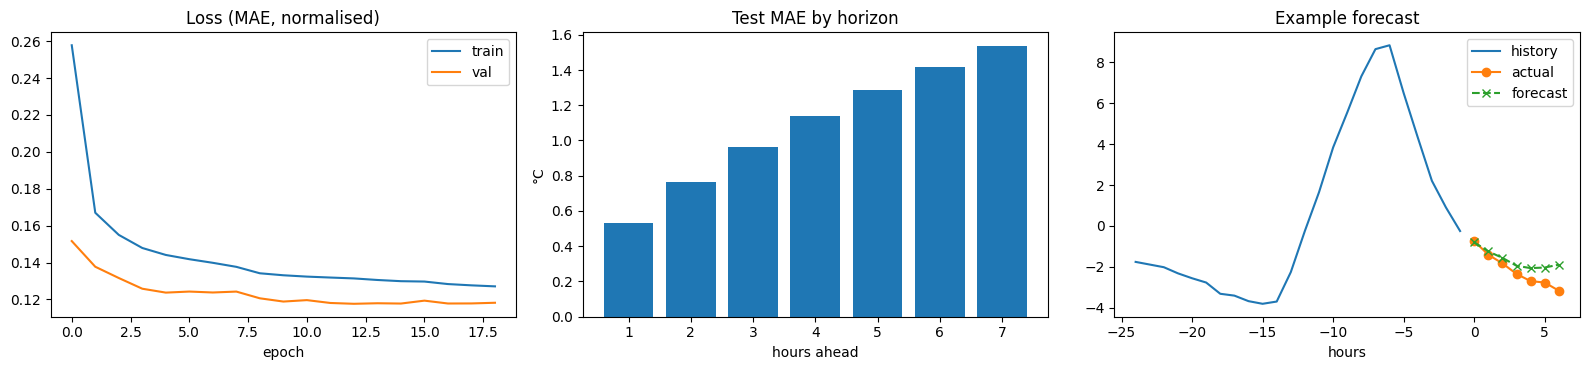

In [5]:
if TRACK == "A":
    # ---------- 7. Evaluate on held-out test set (°C) ----------
    y_pred = model.predict(test_ds, verbose=0)
    pred_c = y_pred * T_std + T_mean
    true_c = y_true * T_std + T_mean
    mae_c  = float(np.abs(pred_c - true_c).mean())
    per_step = np.abs(pred_c - true_c).mean(axis=0)

    metric = round(mae_c, 3)   # MAE in °C for Moodle a5_metric
    print(f"Track A MAE (Moodle a5_metric): {metric} °C")
    print(f"Persistence baseline MAE      : {baseline_mae_c:.3f} °C")
    print("MAE per forecast step (°C):", np.round(per_step, 3))

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
    ax[0].set_title("Loss (MAE, normalised)"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].bar(range(1, H+1), per_step); ax[1].set_title("Test MAE by horizon"); ax[1].set_xlabel("hours ahead"); ax[1].set_ylabel("°C")
    i = 1000
    ax[2].plot(range(-24, 0), (test[i+LOOKBACK-24:i+LOOKBACK, t_idx]*T_std+T_mean), label="history")
    ax[2].plot(range(0, H), true_c[i], "o-", label="actual"); ax[2].plot(range(0, H), pred_c[i], "x--", label="forecast")
    ax[2].set_title("Example forecast"); ax[2].set_xlabel("hours"); ax[2].legend()
    plt.tight_layout(); plt.show()
else:
    print("Skipping Track A")

---
# Track B — Text (AG News)
*Not attempted — Track A chosen (`TRACK = "A"`).*

In [6]:
if TRACK == "B":
    metric = None
    print("Track B not used")
else:
    print("Skipping Track B")

Skipping Track B


---
## Written responses

### Architecture summary (Moodle `a5_architecture`, max 100 words)

The model takes 120 hourly time steps of 17 features: weather measurements plus sine/cosine encodings of hour of day and day of year. A Conv1D layer (32 filters, kernel size 5, ReLU) picks up short-term patterns and reduces noise. An LSTM with 64 units then summarises the whole window, followed by dropout (0.2) and a 64-unit ReLU Dense layer. A final Dense layer with 7 outputs predicts all seven future temperatures at once, so errors do not compound. I trained with Adam and MAE loss, using early stopping and learning-rate reduction.

### Input preparation (Moodle `a5_tokenisation`, max 100 words)

The 10-minute data was reduced to hourly readings. Invalid −9999 wind values were set to 0, wind direction was dropped, and sine/cosine time features were added. I split the data chronologically into 50% train, 25% validation and 25% test, without shuffling. Every feature was standardised using only the training set's mean and standard deviation, to avoid leakage. Sliding windows of 120 hours (5 days) were created with timeseries_dataset_from_array, each paired with the next 7 hourly temperatures as the target. Predictions were converted back to °C for MAE.